# Co-folding at Scale: Boltz-2 and OpenBind-0 on Ray

**AI Drug Discovery & Development Summit 2026 · Hands-on workshop · 90 minutes**

Co-folding models such as Boltz-2 and OpenFold3 predict the binding pose of a small molecule in its protein
target from the protein sequence and the ligand's chemical structure alone. This workshop measures how
accurate those predictions are across three antiviral drug discovery campaigns comprising 2,147 X-ray
crystal structures, and builds the complete workflow on Ray: distributed inference, pose scoring,
fine-tuning, hyperparameter search and a live prediction service.

![The workshop end to end](docs/images/workshop.gif)

| Section | Topic | Ray library | Minutes |
|---|---|---|---|
| 0 | Setup | | 3 |
| 1 | Ray fundamentals | Ray Core | 15 |
| 2 | The data: three drug discovery campaigns | | 6 |
| 3 | Prediction and scoring on a GPU cluster | Ray Data | 18 |
| 4 | Results across 2,147 crystal structures | | 10 |
| 5 | Target-specific fine-tuning of OpenFold3 | Ray Train | 13 |
| 6 | Hyperparameter and inference sweeps | Ray Tune | 5 |
| 7 | Live prediction service and 3D viewer | Ray Serve | 15 |
| 8 | Summary and next steps | | 5 |

**Running the notebook.** Execute the cells in order with **Shift+Enter**. Cells marked ⏱ take several
minutes while GPU nodes start and models load. In the live workshop, the presenter runs the GPU steps
on a shared cluster of 16 L4 GPUs; attendees leave `USE_GPUS = False` in Setup and follow the same cells
with stored results and the shared prediction service. The scientific background, including pose scoring and
campaign structure, is summarized in the [README](README.md#background).

## 0. Setup

This Workspace uses the `aiddd-boltz2-of3` container image, which provides Ray, Boltz-2 and OpenFold3. The
notebook runs on the head node, a CPU-only machine. NVIDIA L4 GPU nodes join the cluster when a cell
requests a GPU and are released once idle. Input data, model weights and the results of the full benchmark
reside on shared storage.

In [ ]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import ray

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

from aiddd_pipeline import (SHARED, TARGETS, BOLTZ_CACHE, OF3_OB_CKPT, OF3_FT_CKPT, Boltz2Predictor,
                            OF3Predictor, load_ligands, validate, make_scorer)
import workshop_helpers as wh

# Data and weights are downloaded once, ahead of the workshop (README step 2)
needed = [TARGETS[t].path("metadata") for t in wh.TARGET_KEYS] + [BOLTZ_CACHE, OF3_OB_CKPT, OF3_FT_CKPT]
missing = [str(p) for p in needed if not p.exists()]
assert not missing, f"Missing {missing}. Run `python scripts/setup_data.py` and `python scripts/prepare_mpro.py` first."

# True runs every GPU step live: the presenter, or anyone running this on their own GPUs.
# Attendees leave it False: GPU steps then use stored results, and Section 7 uses the shared service.
USE_GPUS = False
# The shared prediction service for Section 7. The presenter shares this address.
SERVICE_URL = ""

# GPU type for every GPU step in this notebook. L4 by default; change it here if the session uses another type.
GPU = "L4"

wh.MINE.mkdir(parents=True, exist_ok=True)
print(f"shared data:  {SHARED}")
print(f"your outputs: {wh.MINE}")

# Connect to the Workspace's Ray cluster. Every worker gets the same shared-storage path.
try:
    ray.init(runtime_env={"env_vars": {"AIDDD_SHARED": str(SHARED)}}, ignore_reinit_error=True, logging_level="ERROR")
except ValueError:   # running inside an Anyscale Job, which already sets the environment
    ray.init(ignore_reinit_error=True, logging_level="ERROR")
dashboard = os.environ.get("RAY_OVERRIDE_DASHBOARD_URL") or ray.get_runtime_context().dashboard_url
print(f"Ray Dashboard metrics: {dashboard.rstrip('/')}/#/metrics   (open in a new browser tab)")

## 1. Ray fundamentals

A single Boltz-2 prediction takes about one minute on one GPU. The full benchmark covers 2,147 crystal
structures, three models and three proteins, which amounts to several days of computation on a single GPU.
A discovery team must, in addition, fine-tune models, compare settings and make results available to
medicinal chemists.

Ray is an open-source framework for executing Python across a cluster of machines. Ray Core provides a
small set of primitives (tasks, actors and objects), on which the Ray AI libraries for data processing,
training, tuning and serving are built. This workshop uses all four libraries.

<img src="docs/images/ray/map-of-ray.svg" alt="Ray overview" width="460">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

### 1.1 The cluster

A Ray cluster consists of a **head node** and any number of **worker nodes**. This notebook acts as the
*driver* process on the head node. Every node runs a scheduler and an **object store**, a shared-memory
region that holds results so that other processes can read them without copying. The **autoscaler** on the
head node adds worker nodes when pending work requires resources that are unavailable and removes nodes
that remain idle.

This Workspace has two kinds of worker node: CPU nodes for cheminformatics and scoring, and L4 GPU nodes
for model inference.

<img src="docs/images/ray/ray-cluster.svg" alt="Ray cluster" width="620">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

The current state of the cluster is shown below. Running the cell again later shows nodes joining and
leaving.

In [2]:
def cluster_table():
    rows = []
    for n in ray.nodes():
        if not n["Alive"]:
            continue
        r = n["Resources"]
        rows.append({"node": n["NodeManagerHostname"], "head": "node:__internal_head__" in r,
                     "CPUs": int(r.get("CPU", 0)), "GPUs": int(r.get("GPU", 0)),
                     "GPU type": next((k.split(":")[1] for k in r if k.startswith("accelerator_type:")), ""),
                     "memory (GB)": round(r.get("memory", 0) / 1e9)})
    return pd.DataFrame(rows).sort_values(["head", "GPUs"], ascending=False).reset_index(drop=True)

cluster_table()

,node,head,CPUs,GPUs,GPU type,memory (GB)
0,ip-10-0-80-156,True,0,0,,34
1,ip-10-0-199-62,False,8,1,L4,34
2,ip-10-0-26-46,False,8,1,L4,34


### 1.2 Tasks

Decorating a function with `@ray.remote` turns it into a **task**. Calling `.remote()` schedules the task on
any node with a free CPU and immediately returns an **`ObjectRef`**, a reference to a result that will
exist once the task completes. `ray.get` waits for the result and returns it.

The example below runs a one-second step sixteen times, first in plain Python and then as sixteen Ray
tasks. If no worker node is running yet, the first execution also includes node startup; running the cell
again shows the time for the tasks alone.

In [3]:
def slow_step(i):
    time.sleep(1)          # stands in for 1 second of work, such as featurizing a molecule
    return i * i

t0 = time.time()
serial = [slow_step(i) for i in range(16)]
print(f"plain Python: {time.time() - t0:4.1f} s")

slow_task = ray.remote(slow_step)            # the same function as a Ray task
t0 = time.time()
refs = [slow_task.remote(i) for i in range(16)]
print(f"16 tasks submitted in {time.time() - t0:.3f} s, first reference: {refs[0]}")
parallel = ray.get(refs)
print(f"Ray tasks:    {time.time() - t0:4.1f} s, identical results: {parallel == serial}")

plain Python: 16.0 s
16 tasks submitted in 0.188 s, first reference: ObjectRef(fa31b89f94899135ffffffffffffffffffffffff0300000001000000)
Ray tasks:     4.0 s, identical results: True


A more realistic example computes chemical descriptors for every compound in the three campaigns with
RDKit, split into sixteen chunks across the cluster. Each chunk records the node on which it ran.

In [4]:
@ray.remote(num_cpus=1)
def describe(smiles: list[str]) -> pd.DataFrame:
    # Molecular weight, ring count and hydrogen-bond donors for each SMILES string
    import socket
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Lipinski
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        rows.append({"smiles": s, "mol_weight": Descriptors.MolWt(m) if m else None,
                     "rings": Lipinski.RingCount(m) if m else None,
                     "hbond_donors": Lipinski.NumHDonors(m) if m else None, "node": socket.gethostname()})
    return pd.DataFrame(rows)

smiles = pd.concat([pd.read_csv(TARGETS[t].path("metadata")).smiles.drop_duplicates() for t in wh.TARGET_KEYS])
chunks = np.array_split(smiles.to_numpy(), 16)

t0 = time.time()
props = pd.concat(ray.get([describe.remote(list(c)) for c in chunks]))
print(f"{len(props)} molecules, 16 tasks, {time.time() - t0:.1f} s, {props.node.nunique()} node(s)")
props.drop(columns="node").describe().round(1)

1285 molecules, 16 tasks, 0.7 s, 2 node(s)


,mol_weight,rings,hbond_donors
count,1285.0,1285.0,1285.0
mean,375.7,3.6,1.1
std,122.5,1.7,0.7
min,73.1,0.0,0.0
25%,286.3,2.0,1.0
50%,352.2,3.0,1.0
75%,483.5,5.0,1.0
max,848.4,8.0,4.0


### 1.3 Resources and GPUs

Each task or actor declares the resources it requires: `num_cpus`, `num_gpus` and, optionally, a GPU model
through `accelerator_type`. Ray places it on a node where those resources are free; if none exists, the
autoscaler starts one.

GPU requests may be fractional. With `num_gpus=0.5`, two processes share a single GPU. Section 3 uses this
for the model stages: while one predictor prepares its next molecule on the CPU, the other occupies the
GPU.

The next cell requests two tasks with half an L4 each and proceeds without waiting for them. If no L4 node
is running, the autoscaler starts one, which takes a few minutes. The results are collected at the end of
this section, and the node will then be ready for Section 3. With `USE_GPUS = False` the cell skips the
request; the presenter's screen shows the result.

In [ ]:
@ray.remote(num_gpus=0.5)
def which_gpu(name):
    import socket, subprocess
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip()
    return {"task": name, "node": socket.gethostname(), "GPU ids assigned by Ray": ray.get_gpu_ids(), "GPU": gpu}

gpu_refs = []
if USE_GPUS:
    gpu_refs = [which_gpu.options(accelerator_type=GPU).remote(n) for n in ("predictor A", "predictor B")]   # returns immediately
    print(f"Requested 2 x 0.5 {GPU}. GPUs free right now: {ray.available_resources().get('GPU', 0)}")
else:
    print("USE_GPUS is False: the GPU request runs on the presenter's cluster.")

### 1.4 Objects

Task arguments and results are held as **objects** in the object store. A large input shared by many
tasks, such as a metadata table, a set of fingerprints or model weights, can be stored once with
`ray.put`. Every task then receives the same `ObjectRef` and reads the shared copy on its node, so the data
is transferred only once per node.

<img src="docs/images/ray/objects.png" alt="Objects in Ray" width="300">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

In [6]:
meta_all = pd.concat([pd.read_csv(TARGETS[t].path("metadata")).assign(target=t) for t in wh.TARGET_KEYS])
meta_ref = ray.put(meta_all)                     # stored once in the object store
print(f"metadata: {len(meta_all)} rows, stored as {meta_ref}")

@ray.remote
def count_phase(meta: pd.DataFrame, target: str) -> dict:
    # Ray passes the table itself to the task, resolved from the ObjectRef
    m = meta[meta.target == target]
    return {"target": TARGETS[target].name, "fragment-screen structures": int(m.fragment_screen.sum()),
            "follow-on structures": int((~m.fragment_screen.astype(bool)).sum())}

pd.DataFrame(ray.get([count_phase.remote(meta_ref, t) for t in wh.TARGET_KEYS]))

metadata: 2147 rows, stored as ObjectRef(00ffffffffffffffffffffffffffffffffffffff0300000001e1f505)


,target,fragment-screen structures,follow-on structures
0,EV-A71 2A protease,113,812
1,SARS-CoV-2 Mpro,59,569
2,MERS-CoV Mpro,0,594


### 1.5 Task dependencies and `ray.wait`

An `ObjectRef` can be passed directly to another task. Ray starts the downstream task once its input is
ready and moves the data to where it runs, so an entire graph of work can be submitted at once. `ray.wait`
returns results in the order in which they complete, which is useful for reporting progress or acting on
early results.

In [7]:
@ray.remote
def heaviest(df: pd.DataFrame) -> pd.Series:
    return df.sort_values("mol_weight").iloc[-1]

# describe, then heaviest, submitted together; no ray.get in between
chained = [heaviest.remote(describe.remote(list(c))) for c in chunks[:6]]

pending, finished = chained, 0
while pending:
    ready, pending = ray.wait(pending, num_returns=1)
    finished += 1
    top = ray.get(ready[0])
    print(f"{finished}/6 finished: heaviest molecule {top.mol_weight:6.1f} Da  {top.smiles[:50]}")

1/6 finished: heaviest molecule  249.3 Da  Cc1ccc(OCC(=O)N2CCOCC2)c(C)c1
2/6 finished: heaviest molecule  403.3 Da  CS(=O)(=O)c1ccc(Br)cc1CC(=O)N1CCC[C@H](C(N)=O)C1
3/6 finished: heaviest molecule  385.3 Da  COc1cc(Br)c(CC(=O)N2CCC[C@H](C(N)=O)C2)cc1OC
4/6 finished: heaviest molecule  393.9 Da  COc1cccc(Cl)c1CC(=O)N1C[C@H](C(N)=O)C[C@H](C(=O)NC
5/6 finished: heaviest molecule  415.4 Da  COC[C@]1(C)C[C@H](C(N)=O)CN1C(=O)Cc1cc(Br)ccc1SC
6/6 finished: heaviest molecule  412.9 Da  Cc1nn(C)c(C)c1CC(=O)N[C@@H](CNC(=O)CCl)c1ccc2ccccc


### 1.6 Actors

An **actor** is a Python class decorated with `@ray.remote`. Ray instantiates it once on a single node; it
retains its state between calls and processes method calls in order. Actors are the natural home for
anything expensive to load, such as a co-folding model with several gigabytes of weights resident on a
GPU, and the predictors in Section 3 run as actors.

The actor below loads the EV-A71 2A fragment screen once and then reports the similarity of any new
compound to its nearest fragment.

In [8]:
@ray.remote(num_cpus=1)
class FragmentMemory:
    def __init__(self, fragment_smiles):
        from rdkit import Chem, DataStructs
        from rdkit.Chem import rdFingerprintGenerator
        self.gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
        self.DS, self.Chem = DataStructs, Chem
        self.fps = [self.gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in fragment_smiles]   # loaded once
        self.queries = 0

    def nearest(self, smiles):
        self.queries += 1                                                                      # kept between calls
        fp = self.gen.GetFingerprint(self.Chem.MolFromSmiles(smiles))
        return max(self.DS.BulkTanimotoSimilarity(fp, self.fps))

    def stats(self):
        return f"{len(self.fps)} fragments loaded, {self.queries} queries answered"

meta_ev71 = meta_all[meta_all.target == "ev71-2a"]
memory = FragmentMemory.remote(meta_ev71[meta_ev71.fragment_screen].smiles.unique().tolist())

late = meta_ev71[~meta_ev71.fragment_screen].drop_duplicates("compound_group").tail(5)
sims = ray.get([memory.nearest.remote(s) for s in late.smiles])
print(ray.get(memory.stats.remote()))
pd.DataFrame({"compound": late.compound_group, "similarity to closest fragment (0 to 1)": np.round(sims, 2)})

83 fragments loaded, 5 queries answered


,compound,similarity to closest fragment (0 to 1)
920,x7597a,0.40
921,x7608a,0.20
922,x7613a,0.27
923,x7622a,0.21
924,x7631a,0.25


Many follow-on compounds have a similarity well below 0.5 to every fragment. They contain chemistry that
the fragment screen did not sample, which makes them the more demanding and more relevant test of a model.
Results in this notebook are therefore reported separately for fragments and follow-ons.

### 1.7 Fault tolerance

On a large cluster, failures are routine: a spot instance is reclaimed, a node exhausts its memory, or an
external tool fails on a single input. Ray retries failed tasks (`max_retries`, with
`retry_exceptions=True` to include Python exceptions) and can restart failed actors (`max_restarts`). In
the cell below, each attempt fails with a probability of 30%, yet all twenty tasks complete. Ray logs each
retry, so several retry messages appear above the result.

In [9]:
@ray.remote(max_retries=10, retry_exceptions=True)
def unreliable_step(i):
    import random
    if random.random() < 0.3:
        raise RuntimeError("simulated node failure")
    return i

print(f"{len(ray.get([unreliable_step.remote(i) for i in range(20)]))} of 20 tasks completed")

(raylet) Task unreliable_step failed. There are 10 retries remaining, so the task will be retried. Error: User exception:
ray::unreliable_step() (pid=5903, ip=10.0.26.46)
  File "/tmp/ipykernel_15258/3500811816.py", line 5, in unreliable_step
RuntimeError: simulated node failure


20 of 20 tasks completed


### 1.8 GPU placement and the Ray libraries

The two GPU tasks submitted in Section 1.3 have now had time to start. The cell below waits up to one
minute for them; if the GPU node is still starting, run it again later.

In [ ]:
if not gpu_refs:
    print("Skipped: USE_GPUS is False.")
else:
    ready, pending = ray.wait(gpu_refs, num_returns=len(gpu_refs), timeout=60)
    if pending:
        print(f"The GPU node is still starting. Run this cell again in a few minutes. {cluster_table().GPUs.sum()} GPUs up.")
    else:
        display(pd.DataFrame(ray.get(ready)))

Each task received half of an L4. Depending on availability, Ray placed them on the same GPU or on two
different GPUs. `ray.get_gpu_ids()` reports the device assigned to each process, and the Ray libraries use
it to place each model on the correct GPU.

The remainder of the workshop uses the four Ray libraries, each built on the primitives above:

| Library | Built on | Used for |
|---|---|---|
| **Ray Data** | Tasks for CPU stages, actor pools for model stages, data streamed through the object store | Validation, prediction with Boltz-2 and OpenBind-0, scoring against crystal structures |
| **Ray Train** | One actor per GPU, joined in a PyTorch distributed (DDP) group | Fine-tuning OpenFold3 on two L4 GPUs |
| **Ray Tune** | One trial per configuration, each an actor or a complete Ray Train run, with schedulers for early stopping | Learning-rate sweep and Boltz-2 inference settings |
| **Ray Serve** | Actor replicas behind an HTTP proxy, with replica autoscaling | Live prediction (pose from the fine-tuned model, affinity from Boltz-2) and the 3D results viewer |

![Workflow](docs/images/workflow.png)

Throughout the workshop, keep the **Metrics** page of the Ray Dashboard open in a separate browser tab (the
link is printed in Setup). The panels below are the most informative, together with what a healthy run
looks like on each:

| Metrics panel | ✅ Healthy | ⚠️ Requires attention |
|---|---|---|
| **Node GPU** (utilization) | Close to 100% on every GPU node while Boltz-2 or OpenBind-0 is predicting | Extended periods near 0%: the GPUs are waiting on CPU stages or on model loading |
| **Node GPU Memory (GRAM)** | Stable and below the 24 GB of each L4 | Approaching the limit: reduce `batch_size` or assign each actor a full GPU |
| **Node Count** | GPU nodes join within a few minutes of the first GPU step | No change: no GPUs are available, so set `RUN_LIVE = False` |
| **Scheduler Task State** / **Scheduler Actor State** | Tasks progress from *pending* to *running* to *finished* | Many tasks remain *pending* for minutes: the cluster lacks the requested resources |
| **Object Store Memory** | Rises and falls as Ray Data streams batches through | Grows without receding, or data spills to disk |
| **Ray Data: Rows output / second** | Every operator continues to produce rows | One operator at zero while the others wait: that operator is the bottleneck |

> 🎯 **The three most important panels** are GPU utilization (are the GPUs busy?), Node Count (have the GPU
> nodes started?) and Scheduler Task State (is any work stalled?).

## 2. The data: three drug discovery campaigns

A drug discovery campaign proceeds in two phases:

* **Fragment screen.** Hundreds of small molecules are soaked into protein crystals, and each hit is
  resolved as a crystal structure during the experiment. Predicted poses therefore add little at this
  stage.
* **Follow-on design.** Medicinal chemists elaborate the most promising fragments into larger molecules
  that bind more tightly, often hundreds of compounds over several months. Only a subset is crystallized,
  later and at considerable cost. Reliable predicted poses are most valuable in this phase, which is also
  where prediction is most difficult.

All three targets are viral proteases, enzymes essential for viral replication. Each crystal structure
serves as ground truth, while the models receive only the protein sequence and the compound's SMILES
string.

In [11]:
rows, ligands = [], {}
for t in wh.TARGET_KEYS:
    meta, lig = load_ligands(TARGETS[t])
    ligands[t] = lig
    rows.append({"target": TARGETS[t].name,
                 "crystal structures": len(meta),
                 "unique compounds": len(lig),
                 **{st: int((lig.stage == st).sum()) for st in ["fragment", "early follow-on", "late follow-on"]},
                 "with measured affinity": int(lig.experimental_pKD.notna().sum())})
pd.DataFrame(rows).set_index("target")

,crystal structures,unique compounds,fragment,early follow-on,late follow-on,with measured affinity
target,,,,,,
EV-A71 2A protease,925,699,83,308,308,499
SARS-CoV-2 Mpro,628,308,57,145,106,164
MERS-CoV Mpro,594,285,0,128,157,142


Compound **x7259a** is a late EV-A71 2A follow-on with high measured affinity (pKD 7.9). Its crystal
structure is shown below: the dark sticks represent the compound, and the thin lines show protein residues
within 5 Å of it. Drag to rotate and scroll to zoom.


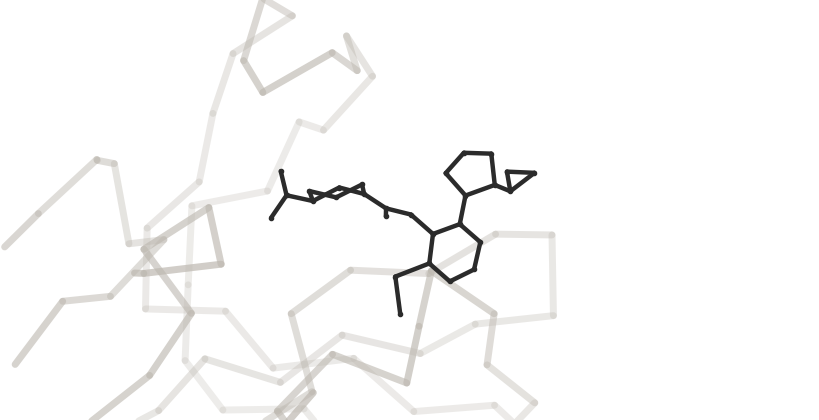

In [12]:
ev71 = wh.load_results("ev71-2a")         # full benchmark results, one row per crystal complex
x7259a = ev71[ev71.complex_name == "A71EV2A-x7259a"].iloc[0]
wh.show_complex(x7259a, models=())

The animation follows a single compound series from a fragment to a potent follow-on, showing each
model's prediction at every step.

![A fragment grown into a potent follow-on](docs/images/campaign.gif)

## 3. Prediction and scoring with Ray Data

This section runs the prediction pipeline on eight late follow-on compounds from EV-A71 2A with three
models. The third is an OpenFold3 checkpoint fine-tuned by the OpenBind team on the EV-A71 2A
fragment-screen structures only, so these eight follow-ons are compounds it has never seen: the run
evaluates the fine-tuned model on held-out data. Predictions are written to a personal output folder, so
every model runs on the GPUs during the session.

A Ray Data `Dataset` is a table partitioned into **blocks** that reside in the object store. Each
processing step operates on blocks in parallel across the cluster.

<img src="docs/images/ray/dataset-arch-with-blocks.svg" alt="Ray Data blocks" width="560">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

The pipeline consists of five steps, each added with `map_batches` or `flat_map`. Ray Data executes them
as a stream: blocks advance to the next step as soon as they are ready, so CPU and GPU steps run
concurrently.

<img src="docs/images/ray/streaming-topology.svg" alt="Streaming execution" width="560">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

| Step | Runs on | Function |
|---|---|---|
| `validate` | CPU | Parses each SMILES string with RDKit |
| `Boltz2Predictor` | L4 GPU, half a GPU per actor | Predicts pose and binding affinity with Boltz-2 |
| `OpenBind0` | L4 GPU, half a GPU per actor | Predicts pose with OpenFold3 using the OpenBind-0 weights |
| `FineTunedOF3` | L4 GPU, half a GPU per actor | Predicts pose with OpenFold3 fine-tuned on the EV-A71 2A fragment screen |
| `make_scorer` | CPU | Superposes each prediction on its crystal structure and computes the ligand RMSD |

The model steps use **actors** (`ActorPoolStrategy`), so each process loads its model once and reuses it
for every batch, and `num_gpus=0.5` places two actors on each GPU: two Boltz-2 actors share one L4, and
one actor of each OpenFold3 model shares the other. The full benchmark used the same classes on eight
GPUs:

![Pipeline architecture](docs/images/architecture.png)

In [13]:
# x7259a plus seven other late follow-ons with a curated crystal structure (non-covalent)
lig = ligands["ev71-2a"]
curated = set(ev71.complex_name)
pool = lig[(lig.stage == "late follow-on") & lig.curated_any & ~lig.covalent.astype(bool) & (lig.ligand_id != "x7259a")]
picked = pd.concat([lig[lig.ligand_id == "x7259a"], pool.sample(7, random_state=1)]).reset_index(drop=True)
picked["complexes"] = picked.complexes.map(lambda cs: [c for c in cs if c in curated])
picked[["ligand_id", "smiles", "stage", "experimental_pKD"]]

,ligand_id,smiles,stage,experimental_pKD
0,x7259a,CSc1ncnc(N2CCC[C@@H]2C2CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,7.9380
1,x7025a,CSc1ncnc(N2CC[C@@H](OC(F)F)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,6.0481
2,x6934a,CSc1ccccc1[C@@H](NC(=O)C1CC1)C(=O)N1CC[C@H](C(N)=O)C1,late follow-on,4.6120
3,x7096a,CSc1ncnc(N2CCC(C(=O)N(C(C)C)C(C)C)CC2)c1CC(=O)N1CCC[C@H]...,late follow-on,6.2253
4,x6827a,CSc1ccc(C2=CC[NH2+]CC2)cc1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,6.3598
5,x7321a,CC[C@H]1CS[C@H](C(N)=O)CN1C(=O)Oc1cc(Br)ccc1SC,late follow-on,4.1702
6,x7154a,CSc1ncnc(N2CCC(N3CCOC3=O)CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,5.9235
7,x7379a,CSc1ccc(-c2cn[nH]c2)cc1OC(=O)N1C[C@@H](C(N)=O)C[C@H]2C[C...,late follow-on,5.6262


In [ ]:
MY_PRED = wh.MINE / "predictions"

class OpenBind0(OF3Predictor):
    # OpenFold3 with the OpenBind-0 weights, writing to your own folder
    def __init__(self, out_dir):
        super().__init__(key="openbind0", ckpt_path=str(OF3_OB_CKPT), target="ev71-2a", out_dir=out_dir)

class FineTunedOF3(OF3Predictor):
    # OpenFold3 fine-tuned on the EV-A71 2A fragment screen only: these follow-ons are held out
    def __init__(self, out_dir):
        super().__init__(key="of3ft", ckpt_path=str(OF3_FT_CKPT), binary="/opt/of3-legacy/bin/run_openfold",
                         target="ev71-2a", out_dir=out_dir)

def gpu_step(actors):
    # `actors` model processes, each on half a GPU; each loads its model once and keeps it
    return dict(batch_size=2, batch_format="pandas", num_gpus=0.5, num_cpus=3, accelerator_type=GPU,
                compute=ray.data.ActorPoolStrategy(size=actors, max_tasks_in_flight_per_actor=1))

ds = (ray.data.from_pandas(picked[["ligand_id", "smiles", "complexes", "stage", "experimental_pKD"]])
      .repartition(4)
      .map_batches(validate, batch_format="pandas")                       # CPU
      .map_batches(Boltz2Predictor, **gpu_step(2),                         # GPU: one L4
                   fn_constructor_kwargs={"target": "ev71-2a", "out_dir": str(MY_PRED / "boltz2")})
      .map_batches(OpenBind0, **gpu_step(1),                               # GPU: half of the other L4
                   fn_constructor_kwargs={"out_dir": str(MY_PRED / "openbind0")})
      .map_batches(FineTunedOF3, **gpu_step(1),                            # GPU: the other half
                   fn_constructor_kwargs={"out_dir": str(MY_PRED / "of3ft")})
      .flat_map(make_scorer(["boltz2", "openbind0", "of3ft"], "ev71-2a")))  # CPU
ds    # execution is lazy: nothing runs until results are requested

⏱ **The next cell takes about five to ten minutes on its first run**, mostly for GPU nodes to start and
models to load. On the **Metrics** page, *Node Count* shows the GPU nodes joining, *Node GPU* shows them
begin predicting, and *Ray Data: Rows output / second* shows the progress of each pipeline step.

`RUN_LIVE` follows `USE_GPUS`. When it is `False`, the cell loads the stored predictions for the same
eight compounds from the full benchmark, and the remainder of the notebook proceeds unchanged.

In [ ]:
RUN_LIVE = USE_GPUS

t0 = time.time()
mine = ds.to_pandas() if RUN_LIVE else ev71[ev71.ligand_id.isin(picked.ligand_id)].reset_index(drop=True)
print(f"{mine.ligand_id.nunique()} compounds, {len(mine)} crystal complexes scored in {(time.time() - t0) / 60:.1f} min")
for k in ("boltz2", "openbind0", "of3ft"):
    print(f"  {wh.MODEL_NAMES[k]:12s} {mine.drop_duplicates('ligand_id')[f'{k}_status'].value_counts().to_dict()}")

view = mine[["complex_name", "boltz2_lig_rmsd", "openbind0_lig_rmsd", "of3ft_lig_rmsd",
             "boltz2_affinity_pred_value"]].copy()
view.columns = ["complex", "Boltz-2 RMSD (Å)", "OpenBind-0 RMSD (Å)", "Fine-tuned RMSD (Å)",
                "Boltz-2 affinity (log10 IC50, µM)"]
(view.style.format(precision=2)
     .map(lambda v: "color:#2E7D4F;font-weight:600" if v < 2 else "color:#B3412E",
          subset=["Boltz-2 RMSD (Å)", "OpenBind-0 RMSD (Å)", "Fine-tuned RMSD (Å)"]))

**Ligand RMSD** is the root-mean-square distance between each predicted ligand atom and its counterpart
in the crystal structure, after the predicted protein has been superposed on the crystal protein. A pose
within **2 Å** (green) is counted as correct; for reference, a carbon-carbon bond is about 1.5 Å long.

The optimal number of predictors per GPU depends on the model. On a single L4, two OpenFold3 processes
nearly double throughput (from 181 to 327 ligands per hour), because the GPU spends less time idle between
molecules. Boltz-2 already keeps the GPU 75% busy with one process, and a second process yields no gain
(88 and 83 ligands per hour). The pipeline settings are derived from measurements such as these:

![Throughput](docs/images/throughput.png)

GPU utilization per node during the full MERS-CoV Mpro benchmark is shown below. Nodes were added as work
arrived and released as each model completed:

![GPU cluster](docs/images/gpu_cluster.png)

In [ ]:
# Your predictions superposed on the crystal: dark = crystal, blue = Boltz-2, orange = OpenBind-0, red = fine-tuned
wh.show_complex(mine[mine.complex_name == "A71EV2A-x7259a"].iloc[0], models=("boltz2", "openbind0", "of3ft"))

For x7259a, OpenBind-0 and the fine-tuned model both reproduce the crystal pose to within half an
ångström (0.40 Å and 0.42 Å in the full benchmark), whereas Boltz-2 places the compound about 13 Å away,
in a different region of the protein. The fine-tuned model never saw x7259a: it learned this protein from
fragment-screen structures alone. The next cell shows two further compounds from this run.

In [ ]:
for _, row in mine.drop_duplicates("ligand_id").iloc[1:3].iterrows():
    wh.show_complex(row, models=("boltz2", "openbind0", "of3ft"), height=340)

## 4. Results across 2,147 crystal structures

The same pipeline was run on all three campaigns before the workshop, requiring one to two hours per target
on eight L4 GPUs. The results below use the curated set: complexes with a valid crystal reference and no
suspected crystallographic artefact. A third model is included, an OpenFold3 checkpoint released by the
OpenBind team after fine-tuning on the EV-A71 2A fragment screen. Section 5 demonstrates how such a
checkpoint is trained.

### 4.1 The live run: every EV-A71 2A late follow-on

While this session ran, the presenter's cluster predicted all **308 EV-A71 2A late follow-on compounds**
with Boltz-2 and OpenBind-0 on 12 L4 GPUs, started at the beginning of the workshop with
`anyscale job submit -f job_live.yaml`. Each prediction is saved as soon as it finishes, so the cell below
can score whatever is done so far: the finished predictions are scored against their crystal structures
with Ray Data on the CPU nodes, and compared with the full benchmark on the same compounds. Run it again
to see the count rise.

In [ ]:
# The most recent live run, or set LIVE_RUN_DIR to a specific one
LIVE_RUN_DIR = None
runs = sorted((SHARED / "workshop" / "live").glob("*"))
live_dir = Path(LIVE_RUN_DIR) if LIVE_RUN_DIR else (runs[-1] if runs else None)

late = ligands["ev71-2a"][ligands["ev71-2a"].stage == "late follow-on"].copy()
if live_dir is None:
    print("No live run found. Start one with: anyscale job submit -f job_live.yaml")
else:
    for k in ("boltz2", "openbind0"):
        cifs = [live_dir / "predictions" / k / f"{l}.cif" for l in late.ligand_id]
        late[f"{k}_cif"] = [str(c) if c.exists() else None for c in cifs]
    done = late.dropna(subset=["boltz2_cif", "openbind0_cif"]).copy()
    print(f"Live run {live_dir.name}: Boltz-2 {late.boltz2_cif.notna().sum()}/{len(late)}, "
          f"OpenBind-0 {late.openbind0_cif.notna().sum()}/{len(late)} compounds predicted")
    done["complexes"] = done.complexes.map(lambda cs: [c for c in cs if c in curated])   # curated crystals only
    done = done[done.complexes.str.len() > 0]
    if len(done):
        live = (ray.data.from_pandas(done[["ligand_id", "complexes", "boltz2_cif", "openbind0_cif"]])
                .repartition(max(1, len(done) // 8))          # eight compounds per CPU task
                .flat_map(make_scorer(["boltz2", "openbind0"], "ev71-2a")).to_pandas())   # CPU tasks
        stored = ev71[ev71.complex_name.isin(live.complex_name)]
        display(pd.DataFrame({f"live run ({len(live)} crystals)": [wh.success(live[f"{k}_lig_rmsd"]) for k in ("boltz2", "openbind0")],
                              "full benchmark, same crystals": [wh.success(stored[f"{k}_lig_rmsd"]) for k in ("boltz2", "openbind0")]},
                             index=["Boltz-2", "OpenBind-0"]).style.format("{:.1f}")
                .set_caption("Share of poses within 2 Å of the crystal structure (%)"))

In [18]:
results = {t: wh.load_results(t) for t in wh.TARGET_KEYS}
table = wh.glance(results)
print("Share of poses within 2 Å of the crystal structure (%)")
table.style.format("{:.1f}").background_gradient(cmap="Greens", vmin=0, vmax=100, axis=None)

Share of poses within 2 Å of the crystal structure (%)


,"EV-A71 2A protease, fragments","EV-A71 2A protease, follow-ons","SARS-CoV-2 Mpro, fragments","SARS-CoV-2 Mpro, follow-ons","MERS-CoV Mpro, follow-ons"
Boltz-2,21.6,3.2,37.5,86.6,86.5
OpenBind-0,28.4,92.7,17.5,89.3,83.3
OF3 fine-tuned (EV-A71 2A),81.1,78.9,7.5,61.9,69.0


Several observations follow from these results:

* Accuracy depends strongly on the target. Boltz-2 is accurate on both coronavirus proteases but predicts
  only 3% of EV-A71 2A follow-on poses correctly.
* The fine-tuned model reaches 79% on EV-A71 2A follow-ons, compared with 3% for Boltz-2. On the two Mpro
  targets it reaches 62% to 69%, below the 83% to 89% achieved by the general-purpose models.
* The fine-tuned model's 81% on EV-A71 2A fragments is measured on its own training data. All other values
  are measured on compounds the model has not seen.

For a new project, these results argue for benchmarking candidate models on the project's own
fragment-screen structures before relying on them for follow-on design. This pipeline can perform that
benchmark on new crystallographic data.

Results by campaign stage for EV-A71 2A:

In [19]:
wh.by_stage(results["ev71-2a"]).style.format("{:.1f}").set_caption("EV-A71 2A: share of poses within 2 Å by stage (%)")

,fragment,early follow-on,late follow-on
Boltz-2,21.6,5.4,1.0
OpenBind-0,28.4,94.1,91.4
OF3 fine-tuned (EV-A71 2A),81.1,79.7,78.1


Cumulative accuracy and accuracy by stage for the two targets with a fragment screen:

![Pose accuracy](docs/images/pose_accuracy.png)

**Binding affinity.** Boltz-2 also predicts binding affinity. The Spearman correlation below measures how
well the predicted values rank compounds relative to the measured values, where 1 denotes an identical
ranking and 0 denotes no relationship.

In [20]:
rho = {}
for t, df in results.items():
    a = df.drop_duplicates("ligand_id")[["experimental_pKD", "boltz2_affinity_pred_value"]].astype(float).dropna()
    # Boltz-2 reports log10(IC50 in µM), where lower means tighter binding, so the sign is flipped
    rho[TARGETS[t].name] = {"Spearman": round((-a.boltz2_affinity_pred_value).corr(a.experimental_pKD, "spearman"), 2),
                            "compounds": len(a), "measurement": TARGETS[t].affinity_label}
pd.DataFrame(rho).T

,Spearman,compounds,measurement
EV-A71 2A protease,0.41,482,pKD
SARS-CoV-2 Mpro,0.86,164,pIC50
MERS-CoV Mpro,0.59,142,pIC50


![Affinity](docs/images/affinity.png)

The next cell identifies other EV-A71 2A follow-on complexes on which the models disagree most, and shows
the compound with the highest measured affinity among them.

13 other EV-A71 2A follow-on complexes with OpenBind-0 under 1 Å and Boltz-2 over 8 Å



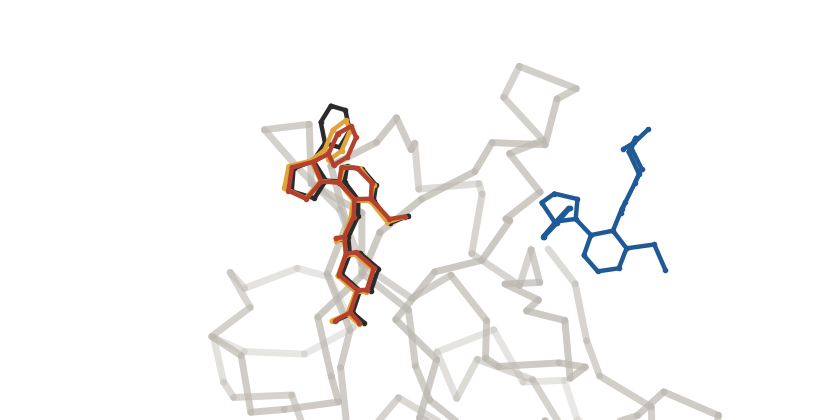

In [21]:
ev = results["ev71-2a"]
disagree = ev[(ev.openbind0_lig_rmsd < 1) & (ev.boltz2_lig_rmsd > 8) & ~ev.fragment_screen]
disagree = disagree[disagree.ligand_id != "x7259a"]      # x7259a was shown above
print(f"{len(disagree)} other EV-A71 2A follow-on complexes with OpenBind-0 under 1 Å and Boltz-2 over 8 Å")
wh.show_complex(disagree.sort_values("experimental_pKD", ascending=False).iloc[0],
                models=("boltz2", "openbind0", "of3ft"))


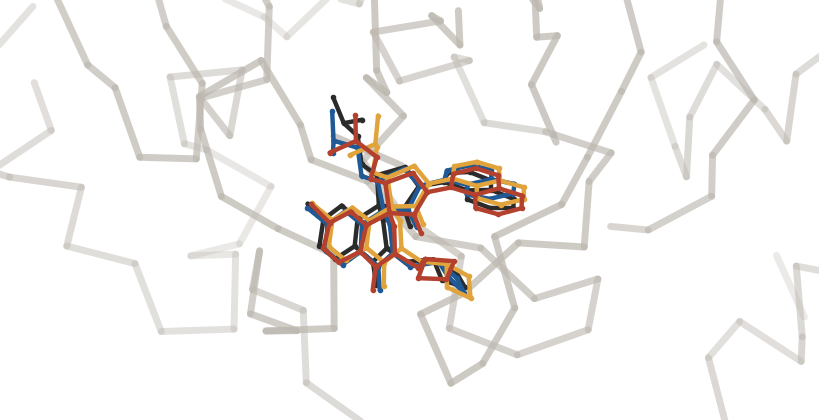

In [22]:
# Enter any complex name from the three targets, for example "MERS-a1994b" or "SARS-5rf4-a"
CID = "MERS-a1994b"
row = pd.concat(results.values()).query("complex_name == @CID").iloc[0]
wh.show_complex(row, models=("boltz2", "openbind0", "of3ft"))

## 5. Target-specific fine-tuning of OpenFold3 with Ray Train

Every campaign begins with a fragment screen that yields dozens of crystal structures of the target
protein. Fine-tuning on these structures adapts a general-purpose model to that protein before the
follow-on phase begins.

This run starts from the OpenBind-0 weights and trains on the **66 EV-A71 2A fragment-screen complexes**.
OpenFold3's PyTorch Lightning training code runs unmodified inside Ray Train, which starts one worker per
GPU, initializes the distributed process group and collects metrics and checkpoints.

<img src="docs/images/ray/train-overview.png" alt="Ray Train" width="560">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

The core of `finetune_ray_train.py`:

```python
trainer = TorchTrainer(
    train_loop_per_worker,                    # OpenFold3's Lightning runner with RayDDPStrategy
    scaling_config=ScalingConfig(num_workers=2, use_gpu=True, accelerator_type="L4"),
    run_config=RunConfig(storage_path=..., checkpoint_config=CheckpointConfig(num_to_keep=1)))
result = trainer.fit()
```

After every optimizer step, each worker calls `ray.train.report(metrics)` with the loss and the
protein-ligand lDDT, and the final weights are returned as a Ray `Checkpoint`.

⏱ **The next cell runs a 20-step fine-tune on two L4 GPUs, which takes five to eight minutes including
startup.** The full run of 150 steps takes about 30 minutes. `RUN_FINETUNE` follows `USE_GPUS`; when it is `False`, the
cell skips training and the plot shows the recorded 150-step run.

In [ ]:
RUN_FINETUNE = USE_GPUS
import json

recorded = sorted((SHARED / "finetune" / "runs").glob("ev71-l4x2-150/checkpoint_*/loss_curve.json"))
recorded = pd.DataFrame(json.loads(recorded[-1].read_text())) if recorded else None

if RUN_FINETUNE:
    import finetune_ray_train as ft
    args = ft.parser().parse_args(["--num-workers", "2", "--max-steps", "20",
                                   "--name", f"workshop-{time.strftime('%H%M%S')}",
                                   "--storage", str(wh.MINE / "finetune"), "--accelerator", GPU])
    ft.check_inputs(args)
    t0 = time.time()
    result = ft.make_trainer(args).fit()
    print(f"\n{args.max_steps} steps on {args.num_workers} GPUs in {(time.time() - t0) / 60:.1f} min")
    print(f"Weights: {result.checkpoint.path}/of3_ev71_ft.pt")
    yours = result.metrics_dataframe

(TrainController pid=259731) [State Transition] SHUTTING_DOWN -> FINISHED.


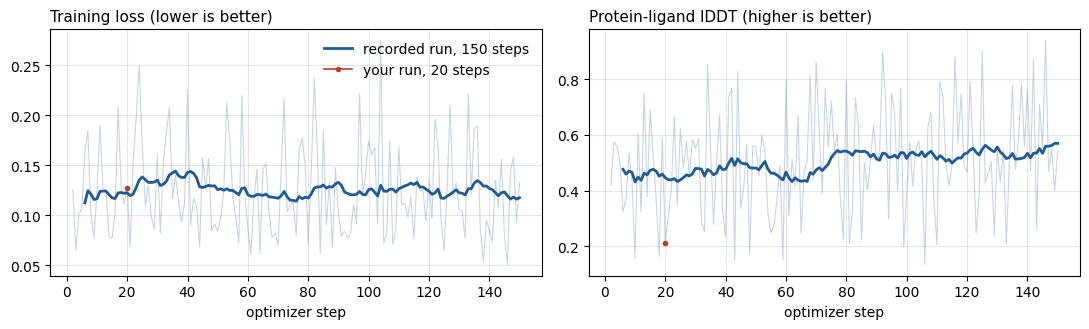

(TrainController pid=16753) [State Transition] SHUTTING_DOWN -> FINISHED.


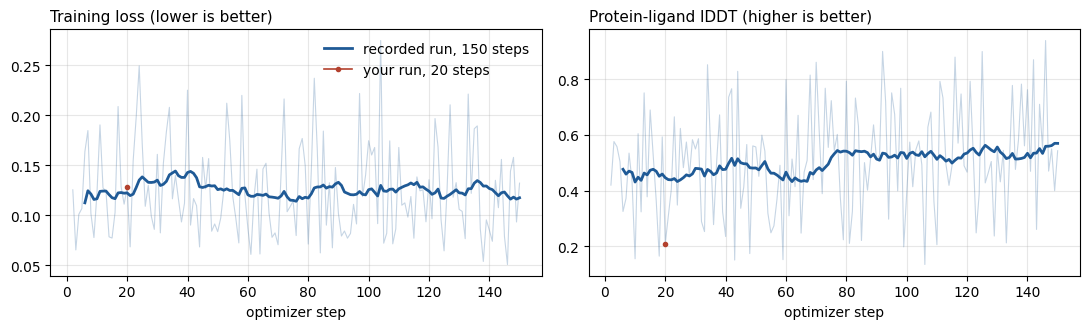

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, name in zip(axes, ["loss", "lddt_inter_protein_ligand_step"],
                         ["Training loss (lower is better)", "Protein-ligand lDDT (higher is better)"]):
    if recorded is not None:
        r = recorded[recorded.step > 1]
        ax.plot(r.step, r[col], color="#1F5A96", alpha=0.25, lw=0.8)
        ax.plot(r.step, r[col].rolling(20, min_periods=5).mean(), color="#1F5A96", lw=2,
                label="recorded run, 150 steps")
    if RUN_FINETUNE:
        y = yours.dropna(subset=[col])
        y = y[y.step > 1]
        ax.plot(y.step, y[col], "o-", color="#B3412E", ms=3, lw=1.2, label="your run, 20 steps")
    ax.set_title(name, loc="left", fontsize=11)
    ax.set_xlabel("optimizer step")
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
plt.tight_layout()

Because training starts from OpenBind-0, which already performs well on this protein, the training loss
changes little; model quality must instead be assessed on held-out compounds. The released fine-tuned
checkpoint in Section 4 was trained on fragments only and predicts 79% of EV-A71 2A follow-on poses
correctly, compared with 3% for Boltz-2. On the two proteases it was not trained on, it reaches 62% to 69%.
Fine-tuned models are therefore best applied to the target for which they were trained.

To benchmark the new weights on every EV-A71 2A compound, submit an Anyscale Job:

```bash
anyscale job submit -f job.yaml --name my-of3ray -- \
  python aiddd_pipeline.py --models of3ray,openbind0 --of3ray-ckpt <your weights>
```

## 6. Hyperparameter and inference sweeps with Ray Tune

Ray Tune runs many trials in parallel, each with its own resources, and its schedulers terminate trials
that fall behind. Both sweeps below were run before the workshop, with `tune_finetune.py` (35 minutes on
four L4 GPUs) and `tune_boltz.py` (62 minutes on eight L4 GPUs).

<img src="docs/images/ray/tune_flow.png" alt="Ray Tune" width="620">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

**Sweep 1: fine-tuning learning rate.** A learning rate that is too low leaves the model largely
unchanged, while one that is too high erodes what it learned during pretraining. Each trial is a complete
Ray Train run. The ASHA scheduler stops trials whose lDDT falls behind, and the surviving trial is
evaluated on 32 held-out early follow-on complexes.

In [25]:
lr = pd.read_csv(SHARED / "finetune" / "runs" / "tune-of3-ev71" / "summary.csv")
lr["result"] = np.where(lr.val_success.notna(),
                        (100 * lr.val_success).round(1).astype(str) + "% within 2 Å on held-out compounds",
                        "stopped by ASHA at step " + lr.steps.astype(int).astype(str))
lr[["lr", "steps", "lddt_avg20", "result"]].style.format({"lr": "{:.0e}", "lddt_avg20": "{:.3f}"}).hide()

lr,steps,lddt_avg20,result
3e-05,120,0.381,stopped by ASHA at step 120
1e-04,120,0.428,stopped by ASHA at step 120
3e-04,150,0.590,93.8% within 2 Å on held-out compounds
1e-03,60,0.386,stopped by ASHA at step 60


ASHA stopped three of the four trials early, so the sweep consumed about 450 GPU-steps rather than the 600
required by a full grid. The selected learning rate of 3e-4 reaches 93.8% on held-out compounds, matching
OpenBind-0 and exceeding the released fine-tune (87.5%).

**Sweep 2: Boltz-2 inference settings on EV-A71 2A.** Each trial evaluates one combination of recycling
steps, diffusion samples and physics-based steering. All eight trials ran concurrently on eight L4 GPUs.

In [26]:
bz = pd.read_csv(SHARED / "tune" / "runs" / "tune-boltz2-ev71" / "summary.csv")
bz["% within 2 Å"] = (100 * bz.success).round(1)
bz["GPU minutes"] = bz.minutes.round(0)
(bz[["setting", "% within 2 Å", "median_rmsd", "GPU minutes"]].rename(columns={"median_rmsd": "median RMSD (Å)"})
   .style.format({"% within 2 Å": "{:.1f}", "median RMSD (Å)": "{:.1f}", "GPU minutes": "{:.0f}"}).bar(subset=["% within 2 Å"], color="#9fb6cf", vmin=0, vmax=100).hide())

setting,% within 2 Å,median RMSD (Å),GPU minutes
rec10_samples5_steered,13.5,3.9,47
rec10_samples5,10.8,3.4,17
rec10_samples1_steered,2.7,3.9,26
rec10_samples1,2.7,4.0,11
rec3_samples1_steered,0.0,3.9,21
rec3_samples5,0.0,4.1,15
rec3_samples5_steered,0.0,4.1,46
rec3_samples1,0.0,4.3,8


The best setting raises Boltz-2 from 0% to 13.5% on this sample, at roughly six times the GPU cost of the
default, whereas OpenBind-0 reaches 92.7% with default settings. The median error remains near 4 Å across
all settings: Boltz-2 places the compound near the pocket but in the wrong orientation, and additional
sampling rarely corrects this. On this target, model selection and fine-tuning have a far greater effect
than additional inference compute.

To run either sweep as an Anyscale Job:

```bash
anyscale job submit -f job.yaml --name tune-ft    -- python tune_finetune.py
anyscale job submit -f job.yaml --name tune-boltz -- python tune_boltz.py
```

## 7. Live prediction service and 3D viewer with Ray Serve

The final step makes the models available to chemists through a web application. Section 4 showed that
the fine-tuned OpenFold3 model predicts EV-A71 2A follow-on poses far better than Boltz-2, but OpenFold3
does not predict binding affinity. The service therefore combines the two: the pose comes from the
fine-tuned model, and the affinity from Boltz-2. `serve_viewer.py` is a Ray Serve application composed of
three deployments:

| Deployment | Resources | Function |
|---|---|---|
| `Viewer` | One CPU | Web page with a table of every crystal complex, a 3D view of each prediction on its crystal structure, and a SMILES input |
| `FineTunedLive` | Half an L4 per replica, one to two replicas | Pose for a new molecule from the fine-tuned OpenFold3, using the same `OF3Predictor` class as the pipeline |
| `Boltz2Live` | Half an L4 per replica, one to two replicas | Binding affinity for a new molecule, using the same `Boltz2Predictor` class as the pipeline |

`Viewer` holds a deployment handle to each model and calls both at the same time, so a request takes as
long as the slower model, not the sum of the two. One replica of each model shares an L4, and each scales
independently of the web page. Repeated molecules are served from a cache.

```python
def build_app(accelerator="L4"):
    gpu = {"num_gpus": 0.5, "accelerator_type": accelerator}
    return Viewer.bind(Boltz2Live.options(ray_actor_options=gpu).bind(),
                       FineTunedLive.options(ray_actor_options=gpu).bind())
```

<img src="docs/images/ray/serve-architecture.svg" alt="Ray Serve architecture" width="600">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

⏱ **Deployment takes one to three minutes** if a GPU node needs to start. With `USE_GPUS = False`, the next
cell connects to the shared service at `SERVICE_URL` instead.

In [ ]:
from ray import serve
import serve_viewer

if USE_GPUS:
    # Three deployments, composed: the Viewer receives a handle to each model deployment
    serve.run(serve_viewer.build_app(accelerator=GPU), name="aiddd", route_prefix="/", blocking=False)
    viewer_url, api_url = wh.serve_link(), "http://localhost:8000"
else:
    assert SERVICE_URL, "Set SERVICE_URL in Setup to the address the presenter shares, and run Setup again."
    viewer_url = api_url = SERVICE_URL.rstrip("/")
    print(f"Shared service: {viewer_url}")

In the viewer, select a model tab and click a complex to compare the predicted compound (green) with the
crystal structure (orange). The viewer runs on the same Ray cluster as the models.

**Prediction from Python.** The next cell submits a new molecule to the service: x7259a with its
methylthio group (S-CH3) replaced by a methoxy group (O-CH3). No crystal structure exists for this
compound. The cell displays the fine-tuned model's predicted pose alongside the crystal pose of x7259a,
together with Boltz-2's predicted affinity.

In [ ]:
import requests

def predict(smiles):
    t0 = time.time()
    r = requests.post(f"{api_url}/predict", json={"smiles": smiles}, timeout=900)
    out = r.json()
    if r.status_code != 200:
        raise RuntimeError(out.get("error"))
    m = out["metrics"]   # Boltz-2's affinity prediction
    print(f"{out['status']} in {time.time() - t0:.0f} s · pose: {out['pose_model']}, ipTM {out.get('pose_iptm') or float('nan'):.2f} · "
          f"affinity {m.get('affinity_pred_value', float('nan')):.2f} log10 IC50 (µM) · "
          f"P(binder) {m.get('affinity_probability_binary', float('nan')):.2f} (Boltz-2)")
    out["cif_path"] = wh.MINE / "live" / f"{out['ligand_id']}.cif"   # a local copy of the pose, to draw it
    out["cif_path"].parent.mkdir(parents=True, exist_ok=True)
    out["cif_path"].write_text(out["cif"])
    return out

NEW = "COc1ncnc(N2CCC[C@@H]2C2CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1"     # x7259a with S replaced by O
out = predict(NEW)
wh.show_analog(out["cif_path"], x7259a, label=f"new molecule ({out['pose_model']}, live)")

The grey ribbon and dark sticks show the crystal structure of x7259a, and the green sticks show the
fine-tuned model's prediction for the new molecule superposed on that crystal. If the new molecule keeps
its parent's binding mode, the two overlap. The pose comes from the model with the best record on this
protein's follow-ons, and the affinity from Boltz-2, the only one of the three models that predicts it.

**Try your own molecule.** Replace the SMILES string below (up to 300 characters). The models predict it
in the EV-A71 2A protease. A new molecule takes about one minute, and a repeated molecule returns
immediately from the cache. On the shared service, requests from the whole room share two L4 GPUs, so
expect to wait behind other attendees.

In [ ]:
MY_SMILES = "CNC(=O)c1nn(C)c2ccccc12"
out = predict(MY_SMILES)
wh.show_prediction(out["cif"], label=f"{MY_SMILES} ({out['pose_model']})")

**Sharing the viewer.** The instructor deploys the same application as an Anyscale Service, which
provides a single public URL backed by two L4 GPUs, so the whole room shares one set of models:

```bash
anyscale service deploy -f service.yaml          # prints the URL to share
anyscale service terminate -n aiddd-viewer       # after the session
```

The application code is identical in both settings: `serve.run` in a Workspace during development, and an
Anyscale Service in production.

## 8. Summary and next steps

In this workshop, a single Ray cluster was used to:

* Run a streaming CPU and GPU pipeline with **Ray Data**, with two model actors per GPU, including all 308
  EV-A71 2A late follow-ons live on 12 L4 GPUs. At full scale, the pipeline processed 2,147 crystal
  structures on eight L4 GPUs.
* Benchmark three models on three targets, showing that accuracy on follow-on compounds varies widely by
  target and by model.
* Fine-tune OpenFold3 on a fragment screen with **Ray Train** on two GPUs.
* Select a learning rate with **Ray Tune** and early stopping, and show that six times more inference
  compute raises Boltz-2 only from 0% to 13.5% on EV-A71 2A.
* Deploy the fine-tuned model (pose) and Boltz-2 (affinity) behind one endpoint, with a 3D viewer, as an
  autoscaling service with **Ray Serve**.

The [README](README.md) provides the scientific background and the complete runbook for this repository,
including running each step as an Anyscale Job and interpreting every output.

Run the final cell to stop the service and release the GPU nodes:

In [ ]:
if USE_GPUS:
    serve.shutdown()
    print("Serve application stopped. Idle GPU nodes will be released within a few minutes.")
else:
    print("Nothing to stop: this notebook used the shared service.")